# Hosting Capacity IEEE 37 barras

## Config geral

* Simulação diária: `mode=daily`, `number=1`, `stepsize=1h`. Nada de snapshot.
* Tensão (PRODIST): 0,93 a 1,05 pu.
* Sobrecarga: corrente acima da `normamps` nas linhas e kVA acima do nominal nos transformadores.
* Tensão por barra: pegar todas as fases, ficar com o mínimo e o máximo entre elas, devolver nome da barra e pu e plotar as 24 horas. Nem toda barra tem 3 fases.

## Métricas de cada cenário

* Sobretensão e subtensão por barra (nome da barra e pu).
* Sobrecarga em linhas e transformadores.
* Fluxo reverso na subestação.
* Perdas totais em kW e em %. Separar linhas, transformadores, storage e outros, em módulo e em percentual.

## Dados fixos

| Item | Valor |
|---|---|
| Soma das cargas de pico | 2457 kW |
| PVs | 8, nas barras 728, 733, 737, 740, 718, 720, 722, 742 |
| `pmpp` por PV | 307,125 kW (8 × 307,125 = 2457 kW) |
| Cargas industriais | `s701a`, `s701b`, `s701c`, `s728`, `s737a`, `s738a` |

As curvas de carga, irradiância e temperatura já estão nas células de preparar cargas e PV.

## Storage (Parte II)

| | Distribuído | Central |
|---|---|---|
| Unidades | 8, uma por PV | 1 |
| Barras | as mesmas dos PVs | 709 |
| `kWrated` | 308 cada | 2464 |
| `kWhrated` | 1250 cada | 10000 |
| `%stored` e `%reserve` | 20 e 20 | 20 e 20 |

Mesma potência e mesma energia total nos dois, senão a comparação não vale.

## Mapa

| Sim | Config |
|---|---|
| 1 | PV false, loadmult=1 |
| 2 | PV false, loadmult=0.2 |
| 3 | PV true, loadmult=1 |
| 4 | PV true, loadmult=0.2 |
| 5 | PV true, loadmult=1, pmpp=x |
| 6 | sim 5 + storage central |
| 7 | sim 5 + storage distribuído |
| 8 | microrrede, ilhamento e corte de carga |

## Setup

Instala as dependências. Só precisa rodar uma vez.

In [144]:
%pip install --upgrade pip
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


#### Imports

In [145]:
import numpy as np    #np, mpl and pd serve as a nicknames
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import os
import dss #OpenDss Module

#### Pasta de trabalho

Ajustar o caminho se mudar de PC.

In [146]:
os.chdir('C:\\Users\\amy\\Desktop\\934\\')   # force going to the working folder (ADJUST FOR YOUR OWN PATH!)
mydir=os.getcwd()                          # mydir stores the working path
print(mydir)                               # just to check if things worked out

C:\Users\amy\Desktop\934


#### Objetos do OpenDSS

In [147]:
dss_engine = dss.DSS
DSSText = dss_engine.Text
DSSCircuit = dss_engine.ActiveCircuit
DSSSolution = dss_engine.ActiveCircuit.Solution

## Simulação 1: PV false, loadmult=1

Referência do alimentador, sem nada de PV e com a carga cheia. Tudo que vier depois se compara com essa.

Ordem: reset, cargas, solve, potência e perdas, potência das cargas, tensão, trafos, linhas, subestação.

#### Reset e compile

Limpa tudo, compila o `ieee37.dss` e guarda as listas de nomes (cargas, barras, trafos, linhas).

In [148]:
#DSSText.Command = 'reset'
DSSText.Command = 'Clear'

DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

#### Listar elementos

Só pra conferir o que foi carregado.

In [149]:
# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

List of elements
Total:73
['Vsource.source', 'Transformer.subxf', 'Transformer.xfm1', 'Line.l1', 'Line.l2', 'Line.l3', 'Line.l4', 'Line.l5', 'Line.l6', 'Line.l7', 'Line.l8', 'Line.l9', 'Line.l10', 'Line.l11', 'Line.l12', 'Line.l13', 'Line.l14', 'Line.l15', 'Line.l16', 'Line.l17', 'Line.l18', 'Line.l19', 'Line.l20', 'Line.l21', 'Line.l22', 'Line.l23', 'Line.l24', 'Line.l25', 'Line.l26', 'Line.l27', 'Line.l28', 'Line.l29', 'Line.l30', 'Line.l31', 'Line.l32', 'Line.l33', 'Line.l34', 'Line.l35', 'Transformer.reg1a', 'RegControl.creg1a', 'Transformer.reg1c', 'RegControl.creg1c', 'Line.jumper', 'Load.s701a', 'Load.s701b', 'Load.s701c', 'Load.s712c', 'Load.s713c', 'Load.s714a', 'Load.s714b', 'Load.s718a', 'Load.s720c', 'Load.s722b', 'Load.s722c', 'Load.s724b', 'Load.s725b', 'Load.s727c', 'Load.s728', 'Load.s729a', 'Load.s730c', 'Load.s731b', 'Load.s732c', 'Load.s733a', 'Load.s734c', 'Load.s735c', 'Load.s736b', 'Load.s737a', 'Load.s738a', 'Load.s740c', 'Load.s741c', 'Load.s742a', 'Load.s742b',

#### Preparar cargas

Cria as curvas residencial e industrial e liga cada carga na sua. Industriais: `s701a`, `s701b`, `s701c`, `s728`, `s737a`, `s738a`. O resto é residencial.

In [150]:
# industriais (os outros são residenciais), em minúsculo
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

#### Solve

Diário, 24 passos de 1h. Limites de tensão 0,93 a 1,05 pu.

In [151]:
DSSText.Command = 'reset'

DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'

#Configure power flow options

#DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set number=1'
DSSText.Command = 'set steps=1h'
DSSText.Command = 'set hour=0'          # começa na hora 0
DSSText.Command = 'set DemandInterval=true'
DSSText.Command = 'set overloadreport=true'
DSSText.Command = 'set voltexceptionreport=true'
DSSText.Command = 'set DIVerbose=true'
DSSText.Command = 'closeDI'

# onde vou guardar o que acontece em cada hora
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # com number=1 resolve só a hora h

    # subestação (sem abs: negativo = fornecendo, positivo = fluxo reverso)
    Total_Act_Power.append(DSSCircuit.TotalPower[0])
    Total_React_Power.append(DSSCircuit.TotalPower[1])
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar

    # cargas
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#### Potência e perdas

Totais do circuito. O `TotalPower` vem negativo quando a subestação fornece energia, por isso o `abs` no percentual.

In [152]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)

Total kW delivered to the network: -1235.336 kW
Total kVAr delivered to the network: -665.302 kvar
Total active losses: 35.177 kW
Percent losses: 2.848%
Total reactive losses: 79.840 kVAr


#### Potência das cargas

kW e kvar de cada carga nas 24 horas.

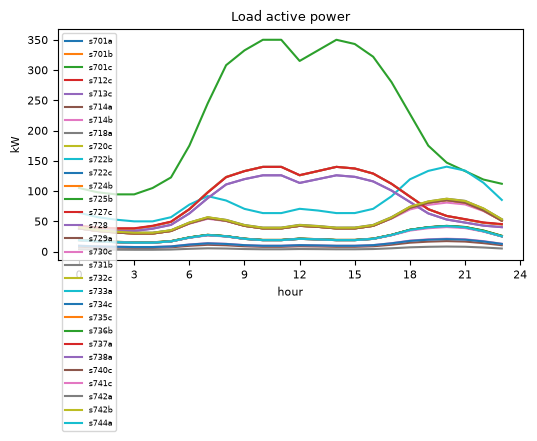

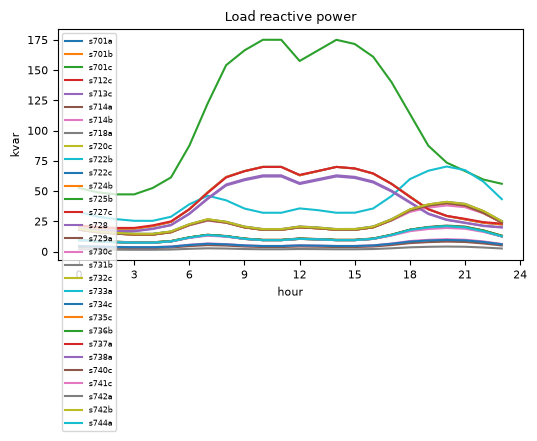

In [153]:
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # ou o Solve que você usa no loop
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers   # [P1, Q1, P2, Q2, ...]
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)



ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

#### Violações de tensão

Por fase, depois mínimo e máximo por barra. Ver quem passa de 1,05 ou cai de 0,93.

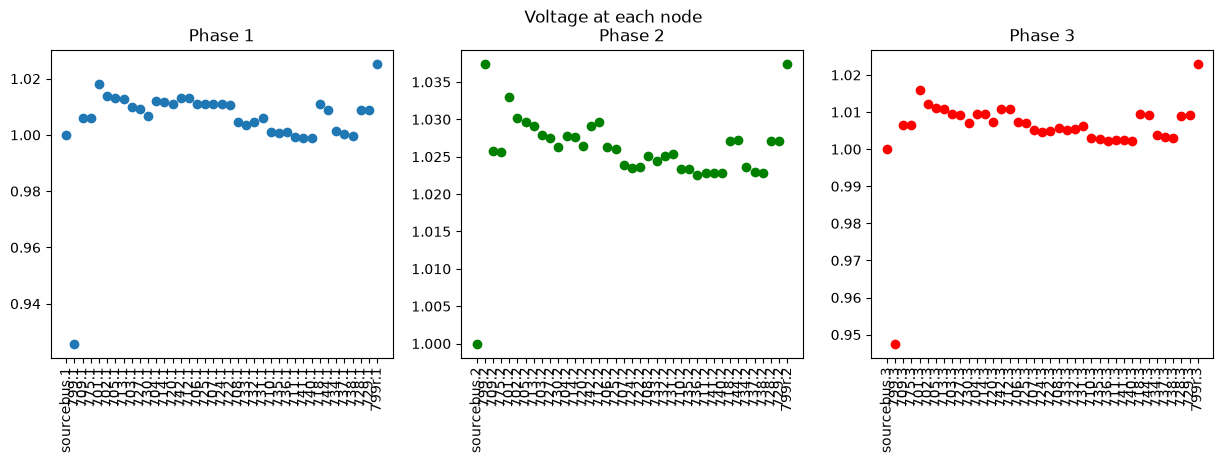

In [154]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

#### Corrente nos transformadores

Carregamento em relação ao nominal. Os reguladores ficam de fora.

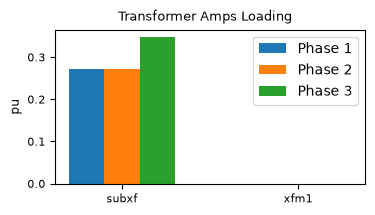

In [155]:
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()

#### Corrente nas linhas

Máximo entre as fases dividido pela `normamps`. Acima de 1 pu é sobrecarga.

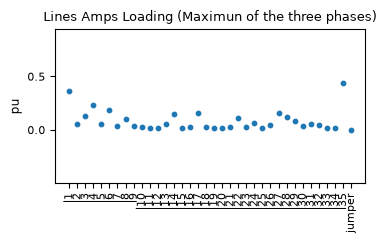

In [156]:
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)
plt.show()

#### Subestação

Potência ativa, reativa e perdas nas 24 horas. Atenção: o `abs` esconde o fluxo reverso, então pra enxergar ele o sinal original precisa aparecer no gráfico.

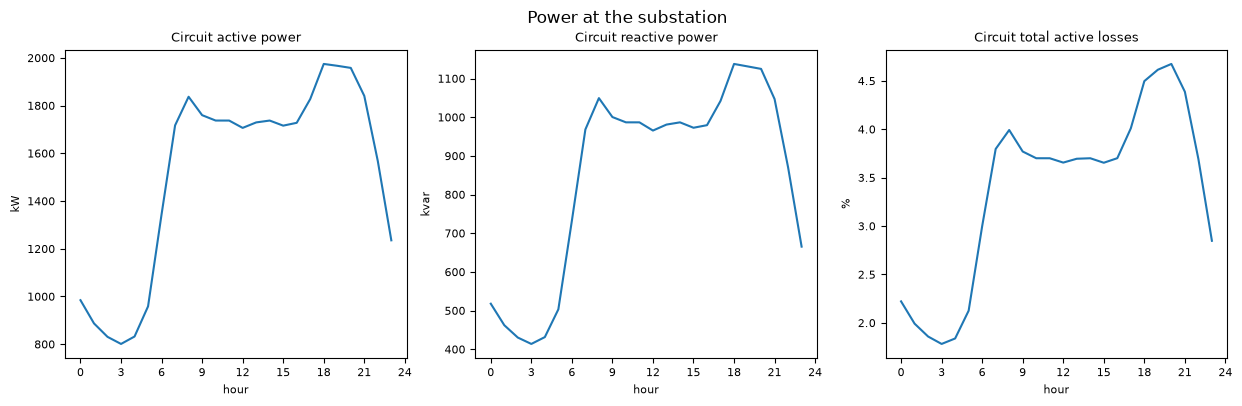

In [157]:
#*******---------Results for the substation
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []

for h in range(24):
    DSSSolution.Solve()
    Total_Act_Power.append(abs(DSSCircuit.TotalPower[0]))
    Total_React_Power.append(abs(DSSCircuit.TotalPower[1]))
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar
#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

## Simulação 2: PV false, loadmult=0.2

Mesma coisa da 1, só que com carga a 20%. No solve entra `set loadmult=0.2`.

Olhar: se alguma barra sobe de tensão mesmo sem PV.

#### Reset e compile

Limpa tudo, compila o `ieee37.dss` e guarda as listas de nomes (cargas, barras, trafos, linhas).

In [158]:
DSSText.Command = 'reset'
DSSText.Command = 'Clear'

DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

#### Listar elementos

Só pra conferir o que foi carregado.

In [159]:
# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

List of elements
Total:73
['Vsource.source', 'Transformer.subxf', 'Transformer.xfm1', 'Line.l1', 'Line.l2', 'Line.l3', 'Line.l4', 'Line.l5', 'Line.l6', 'Line.l7', 'Line.l8', 'Line.l9', 'Line.l10', 'Line.l11', 'Line.l12', 'Line.l13', 'Line.l14', 'Line.l15', 'Line.l16', 'Line.l17', 'Line.l18', 'Line.l19', 'Line.l20', 'Line.l21', 'Line.l22', 'Line.l23', 'Line.l24', 'Line.l25', 'Line.l26', 'Line.l27', 'Line.l28', 'Line.l29', 'Line.l30', 'Line.l31', 'Line.l32', 'Line.l33', 'Line.l34', 'Line.l35', 'Transformer.reg1a', 'RegControl.creg1a', 'Transformer.reg1c', 'RegControl.creg1c', 'Line.jumper', 'Load.s701a', 'Load.s701b', 'Load.s701c', 'Load.s712c', 'Load.s713c', 'Load.s714a', 'Load.s714b', 'Load.s718a', 'Load.s720c', 'Load.s722b', 'Load.s722c', 'Load.s724b', 'Load.s725b', 'Load.s727c', 'Load.s728', 'Load.s729a', 'Load.s730c', 'Load.s731b', 'Load.s732c', 'Load.s733a', 'Load.s734c', 'Load.s735c', 'Load.s736b', 'Load.s737a', 'Load.s738a', 'Load.s740c', 'Load.s741c', 'Load.s742a', 'Load.s742b',

#### Preparar cargas

Cria as curvas residencial e industrial e liga cada carga na sua. Industriais: `s701a`, `s701b`, `s701c`, `s728`, `s737a`, `s738a`. O resto é residencial.

In [160]:
# industriais (os outros são residenciais), em minúsculo
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

#### Solve

Diário, 24 passos de 1h. Limites de tensão 0,93 a 1,05 pu.

In [161]:
DSSText.Command = 'set loadmult=0.2'

DSSText.Command = 'reset'

DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'

#Configure power flow options

#DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set number=1'
DSSText.Command = 'set steps=1h'
DSSText.Command = 'set hour=0'          # começa na hora 0
DSSText.Command = 'set DemandInterval=true'
DSSText.Command = 'set overloadreport=true'
DSSText.Command = 'set voltexceptionreport=true'
DSSText.Command = 'set DIVerbose=true'
DSSText.Command = 'closeDI'

# onde vou guardar o que acontece em cada hora
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # com number=1 resolve só a hora h

    # subestação (sem abs: negativo = fornecendo, positivo = fluxo reverso)
    Total_Act_Power.append(DSSCircuit.TotalPower[0])
    Total_React_Power.append(DSSCircuit.TotalPower[1])
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar

    # cargas
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#### Potência e perdas

Totais do circuito. O `TotalPower` vem negativo quando a subestação fornece energia, por isso o `abs` no percentual.

In [162]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)

Total kW delivered to the network: -241.499 kW
Total kVAr delivered to the network: -113.520 kvar
Total active losses: 1.321 kW
Percent losses: 0.547%
Total reactive losses: -3.687 kVAr


#### Potência das cargas

kW e kvar de cada carga nas 24 horas.

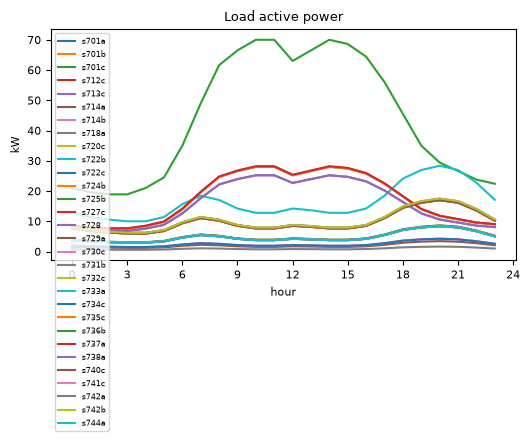

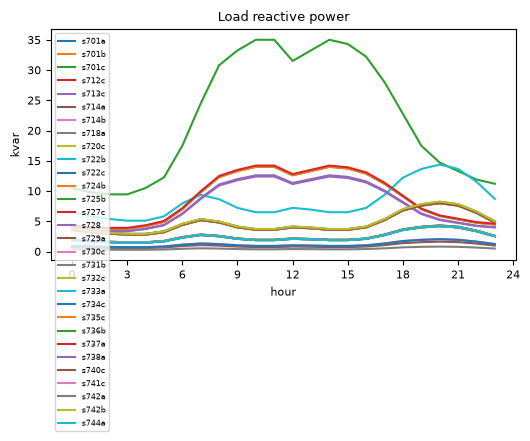

In [163]:
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # ou o Solve que você usa no loop
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers   # [P1, Q1, P2, Q2, ...]
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)



ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

#### Violações de tensão

Por fase, depois mínimo e máximo por barra. Ver quem passa de 1,05 ou cai de 0,93.

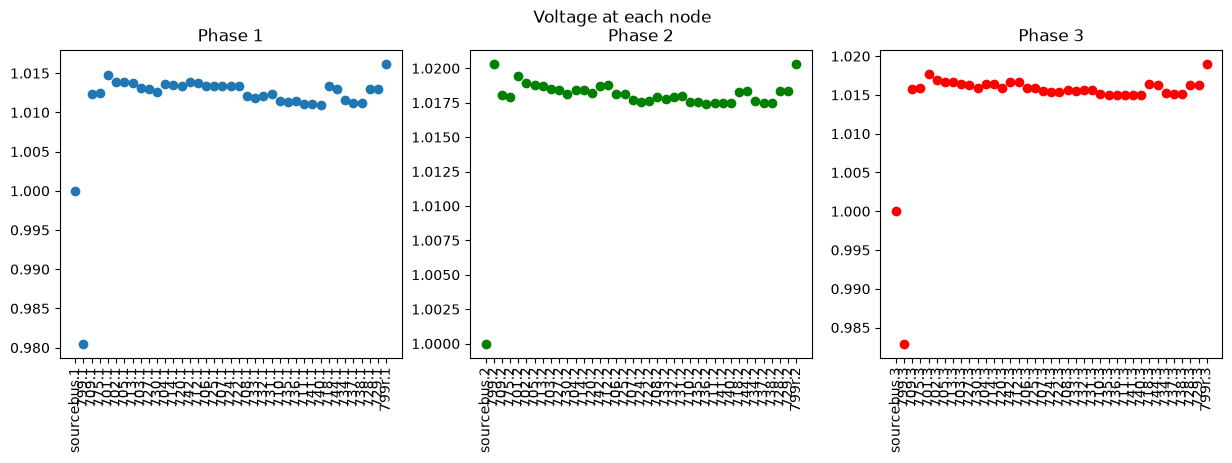

In [164]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

#### Corrente nos transformadores

Carregamento em relação ao nominal. Os reguladores ficam de fora.

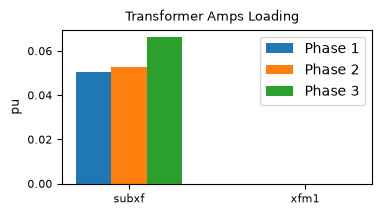

In [165]:
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()

#### Corrente nas linhas

Máximo entre as fases dividido pela `normamps`. Acima de 1 pu é sobrecarga.

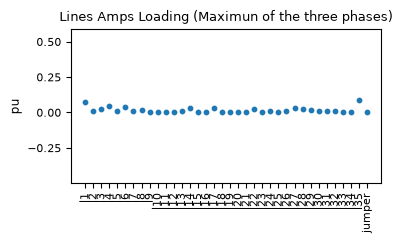

In [166]:
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)
plt.show()

#### Subestação, resumo rápido

Valores finais do solve, sem gráfico.

In [167]:
#*******---------Results for the substation
Total_Act_Power = DSSCircuit.TotalPower[0]
Total_React_Power = DSSCircuit.TotalPower[1]
Total_Act_Losses = DSSCircuit.Losses[0]
Total_React_Losses = DSSCircuit.Losses[1]

print("Total Active Power:", Total_Act_Power)
print("Total Reactive Power:", Total_React_Power)
print("Total Active Losses:", Total_Act_Losses)
print("Total Reactive Losses:", Total_React_Losses)



Total Active Power: -241.49893796735293
Total Reactive Power: -113.51989575636895
Total Active Losses: 1320.848474405346
Total Reactive Losses: -3687.4616811667593


#### Subestação, 24 horas

Potência ativa, reativa e perdas ao longo do dia. Atenção: o `abs` esconde o fluxo reverso.

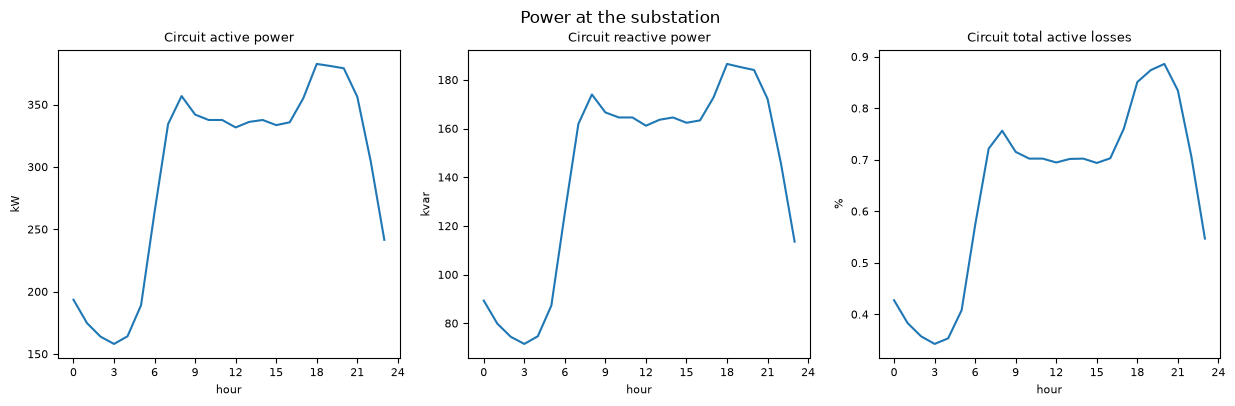

In [168]:
#*******---------Results for the substation
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []

for h in range(24):
    DSSSolution.Solve()
    Total_Act_Power.append(abs(DSSCircuit.TotalPower[0]))
    Total_React_Power.append(abs(DSSCircuit.TotalPower[1]))
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar
#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

## Simulação 3: PV true, loadmult=1

Igual à 1, mas roda o `pvpsys` antes do solve.

Olhar: sobretensão perto das barras com PV e se aparece fluxo reverso na subestação.

#### Reset e compile

Limpa tudo, compila o `ieee37.dss` e guarda as listas de nomes (cargas, barras, trafos, linhas).

In [169]:
DSSText.Command = 'reset'
DSSText.Command = 'Clear'
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

#### Listar elementos

Só pra conferir o que foi carregado.

In [170]:
# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

List of elements
Total:73
['Vsource.source', 'Transformer.subxf', 'Transformer.xfm1', 'Line.l1', 'Line.l2', 'Line.l3', 'Line.l4', 'Line.l5', 'Line.l6', 'Line.l7', 'Line.l8', 'Line.l9', 'Line.l10', 'Line.l11', 'Line.l12', 'Line.l13', 'Line.l14', 'Line.l15', 'Line.l16', 'Line.l17', 'Line.l18', 'Line.l19', 'Line.l20', 'Line.l21', 'Line.l22', 'Line.l23', 'Line.l24', 'Line.l25', 'Line.l26', 'Line.l27', 'Line.l28', 'Line.l29', 'Line.l30', 'Line.l31', 'Line.l32', 'Line.l33', 'Line.l34', 'Line.l35', 'Transformer.reg1a', 'RegControl.creg1a', 'Transformer.reg1c', 'RegControl.creg1c', 'Line.jumper', 'Load.s701a', 'Load.s701b', 'Load.s701c', 'Load.s712c', 'Load.s713c', 'Load.s714a', 'Load.s714b', 'Load.s718a', 'Load.s720c', 'Load.s722b', 'Load.s722c', 'Load.s724b', 'Load.s725b', 'Load.s727c', 'Load.s728', 'Load.s729a', 'Load.s730c', 'Load.s731b', 'Load.s732c', 'Load.s733a', 'Load.s734c', 'Load.s735c', 'Load.s736b', 'Load.s737a', 'Load.s738a', 'Load.s740c', 'Load.s741c', 'Load.s742a', 'Load.s742b',

#### Preparar cargas

Cria as curvas residencial e industrial e liga cada carga na sua. Industriais: `s701a`, `s701b`, `s701c`, `s728`, `s737a`, `s738a`. O resto é residencial.

In [171]:
# industriais (os outros são residenciais), em minúsculo
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

#### PV systems

8 PVs com `pmpp=307.125` (soma = 2457 kW, igual à soma das cargas). Também cria as curvas de irradiância, temperatura, eficiência e PvsT.

In [172]:
#Define curves fo the PV System: TempxPerature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'


DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'


DSSText.Command = 'New loadshape.Irrad npts=24 interval=1  mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0] '


DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'

#### Solve

Diário, 24 passos de 1h. Limites de tensão 0,93 a 1,05 pu.

In [173]:
DSSText.Command = 'reset'

DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'

#Configure power flow options

#DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set number=1'
DSSText.Command = 'set steps=1h'
DSSText.Command = 'set hour=0'          # começa na hora 0
DSSText.Command = 'set DemandInterval=true'
DSSText.Command = 'set overloadreport=true'
DSSText.Command = 'set voltexceptionreport=true'
DSSText.Command = 'set DIVerbose=true'
DSSText.Command = 'closeDI'

# onde vou guardar o que acontece em cada hora
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # com number=1 resolve só a hora h

    # subestação (sem abs: negativo = fornecendo, positivo = fluxo reverso)
    Total_Act_Power.append(DSSCircuit.TotalPower[0])
    Total_React_Power.append(DSSCircuit.TotalPower[1])
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar

    # cargas
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#### Potência e perdas

Totais do circuito. O `TotalPower` vem negativo quando a subestação fornece energia, por isso o `abs` no percentual.

In [174]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)

Total kW delivered to the network: -1235.336 kW
Total kVAr delivered to the network: -665.302 kvar
Total active losses: 35.177 kW
Percent losses: 2.848%
Total reactive losses: 79.840 kVAr


#### Potência das cargas

kW e kvar de cada carga nas 24 horas.

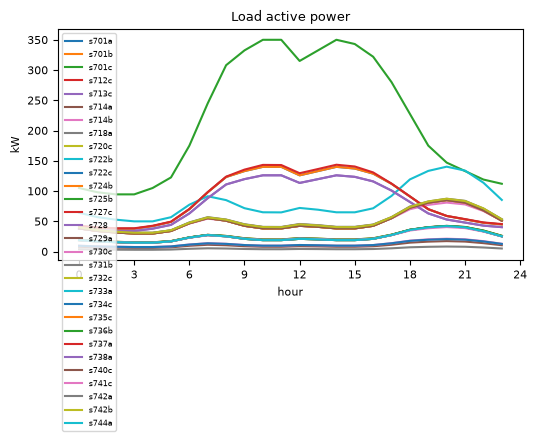

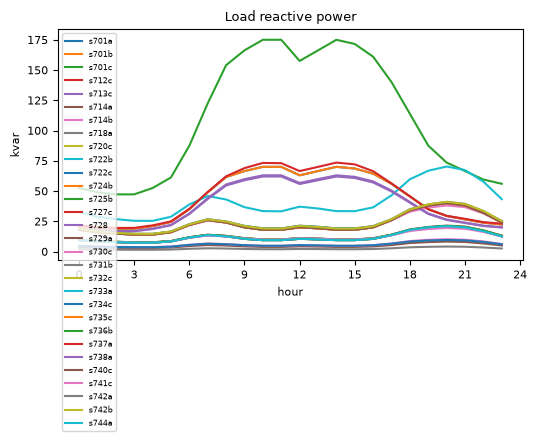

In [175]:
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # ou o Solve que você usa no loop
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers   # [P1, Q1, P2, Q2, ...]
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)



ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

#### Violações de tensão

Por fase, depois mínimo e máximo por barra. Ver quem passa de 1,05 ou cai de 0,93.

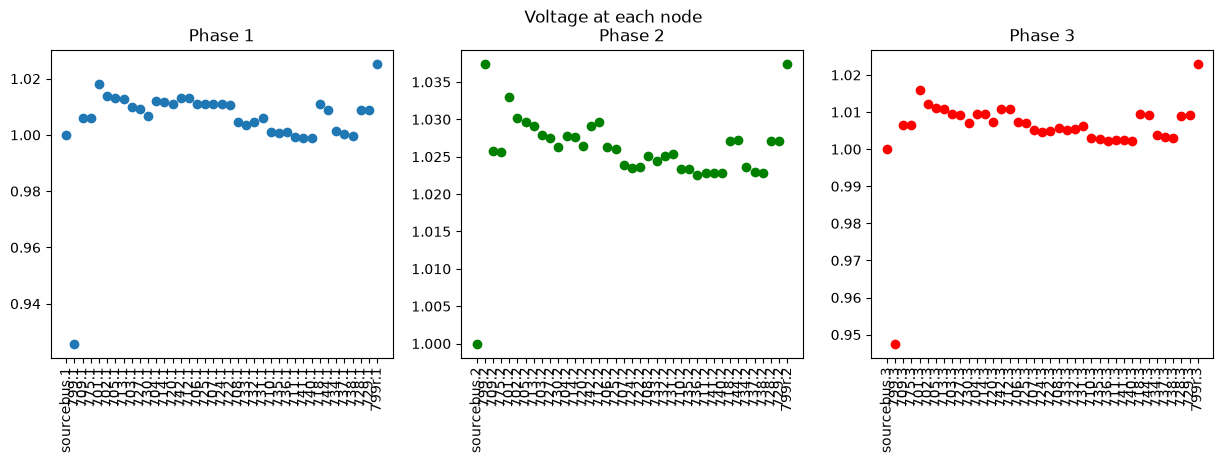

In [176]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

#### Corrente nos transformadores

Carregamento em relação ao nominal. Os reguladores ficam de fora.

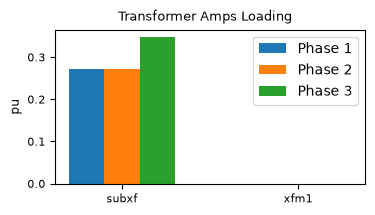

In [177]:
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()

#### Corrente nas linhas

Máximo entre as fases dividido pela `normamps`. Acima de 1 pu é sobrecarga.

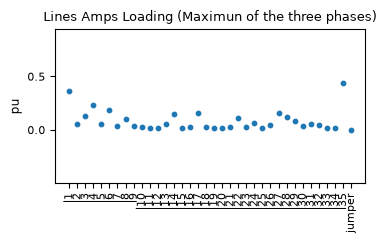

In [178]:
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)
plt.show()

#### Subestação

Potência ativa, reativa e perdas nas 24 horas. Atenção: o `abs` esconde o fluxo reverso, então pra enxergar ele o sinal original precisa aparecer no gráfico.

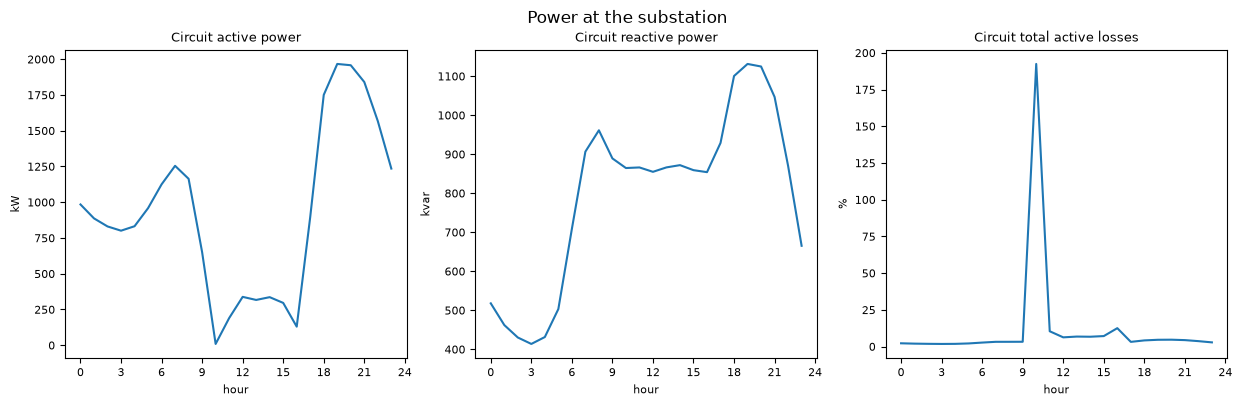

In [179]:
#*******---------Results for the substation
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []

for h in range(24):
    DSSSolution.Solve()
    Total_Act_Power.append(abs(DSSCircuit.TotalPower[0]))
    Total_React_Power.append(abs(DSSCircuit.TotalPower[1]))
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar
#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

## Simulação 4: PV true, loadmult=0.2

PV ligado com carga leve, ou seja, geração sobrando. No solve entra `set loadmult=0.2`.

Olhar: é o caso mais provável de sobretensão e fluxo reverso.

#### Reset e compile

Limpa tudo, compila o `ieee37.dss` e guarda as listas de nomes (cargas, barras, trafos, linhas).

In [180]:
DSSText.Command = 'reset'
DSSText.Command = 'Clear'

DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

#### Listar elementos

Só pra conferir o que foi carregado.

In [181]:
# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

List of elements
Total:73
['Vsource.source', 'Transformer.subxf', 'Transformer.xfm1', 'Line.l1', 'Line.l2', 'Line.l3', 'Line.l4', 'Line.l5', 'Line.l6', 'Line.l7', 'Line.l8', 'Line.l9', 'Line.l10', 'Line.l11', 'Line.l12', 'Line.l13', 'Line.l14', 'Line.l15', 'Line.l16', 'Line.l17', 'Line.l18', 'Line.l19', 'Line.l20', 'Line.l21', 'Line.l22', 'Line.l23', 'Line.l24', 'Line.l25', 'Line.l26', 'Line.l27', 'Line.l28', 'Line.l29', 'Line.l30', 'Line.l31', 'Line.l32', 'Line.l33', 'Line.l34', 'Line.l35', 'Transformer.reg1a', 'RegControl.creg1a', 'Transformer.reg1c', 'RegControl.creg1c', 'Line.jumper', 'Load.s701a', 'Load.s701b', 'Load.s701c', 'Load.s712c', 'Load.s713c', 'Load.s714a', 'Load.s714b', 'Load.s718a', 'Load.s720c', 'Load.s722b', 'Load.s722c', 'Load.s724b', 'Load.s725b', 'Load.s727c', 'Load.s728', 'Load.s729a', 'Load.s730c', 'Load.s731b', 'Load.s732c', 'Load.s733a', 'Load.s734c', 'Load.s735c', 'Load.s736b', 'Load.s737a', 'Load.s738a', 'Load.s740c', 'Load.s741c', 'Load.s742a', 'Load.s742b',

#### Preparar cargas

Cria as curvas residencial e industrial e liga cada carga na sua. Industriais: `s701a`, `s701b`, `s701c`, `s728`, `s737a`, `s738a`. O resto é residencial.

In [182]:
# industriais (os outros são residenciais), em minúsculo
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

#### PV systems

8 PVs com `pmpp=307.125` (soma = 2457 kW, igual à soma das cargas). Também cria as curvas de irradiância, temperatura, eficiência e PvsT.

In [183]:
#Define curves fo the PV System: TempxPerature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'


DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'


DSSText.Command = 'New loadshape.Irrad npts=24 interval=1  mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0] '


DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'

#### Solve

Diário, 24 passos de 1h. Limites de tensão 0,93 a 1,05 pu.

In [184]:
DSSText.Command = 'set loadmult=0.2'

DSSText.Command = 'reset'

DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'

#Configure power flow options

#DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set number=1'
DSSText.Command = 'set steps=1h'
DSSText.Command = 'set hour=0'          # começa na hora 0
DSSText.Command = 'set DemandInterval=true'
DSSText.Command = 'set overloadreport=true'
DSSText.Command = 'set voltexceptionreport=true'
DSSText.Command = 'set DIVerbose=true'
DSSText.Command = 'closeDI'

# onde vou guardar o que acontece em cada hora
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # com number=1 resolve só a hora h

    # subestação (sem abs: negativo = fornecendo, positivo = fluxo reverso)
    Total_Act_Power.append(DSSCircuit.TotalPower[0])
    Total_React_Power.append(DSSCircuit.TotalPower[1])
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar

    # cargas
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#### Potência e perdas

Totais do circuito. O `TotalPower` vem negativo quando a subestação fornece energia, por isso o `abs` no percentual.

In [185]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)

Total kW delivered to the network: -240.915 kW
Total kVAr delivered to the network: -113.199 kvar
Total active losses: 1.318 kW
Percent losses: 0.547%
Total reactive losses: -3.657 kVAr


#### Potência das cargas

kW e kvar de cada carga nas 24 horas.

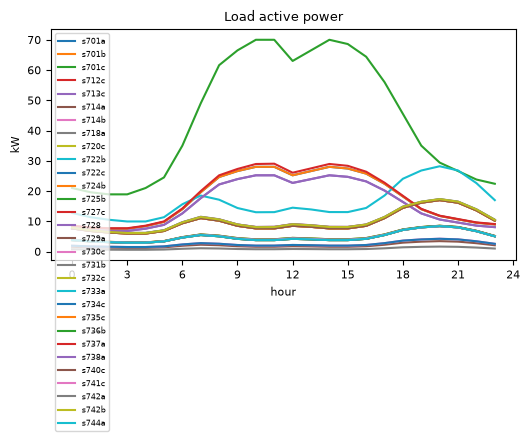

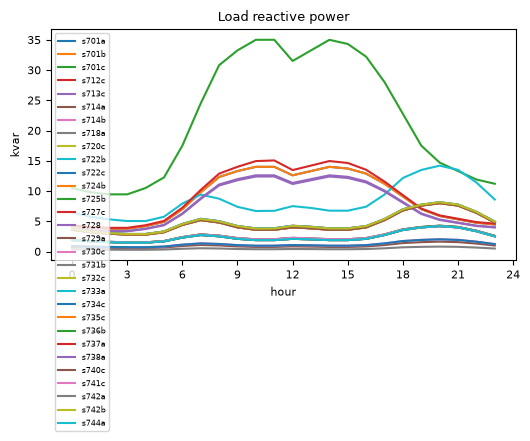

In [186]:
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # ou o Solve que você usa no loop
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers   # [P1, Q1, P2, Q2, ...]
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)



ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

#### Violações de tensão

Por fase, depois mínimo e máximo por barra. Ver quem passa de 1,05 ou cai de 0,93.

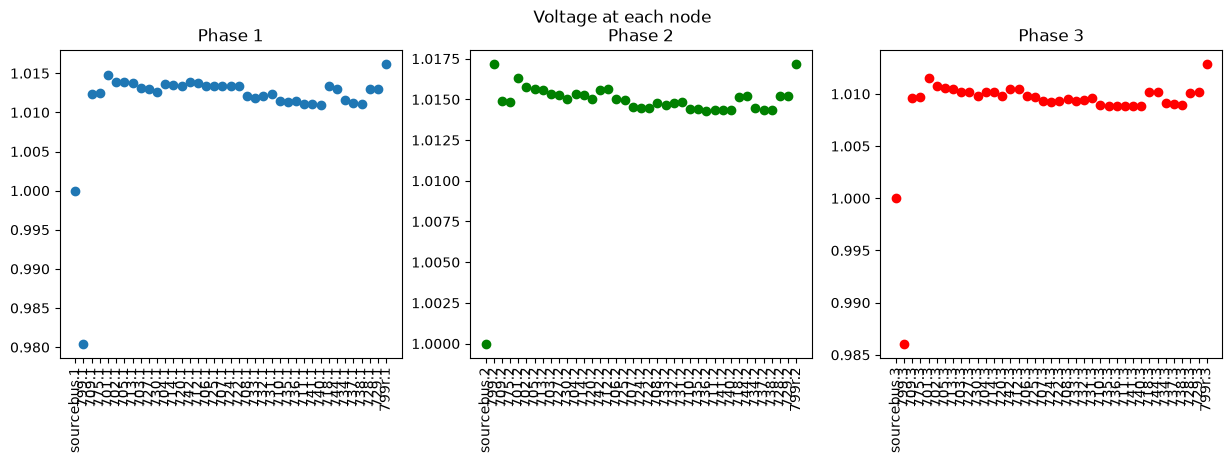

In [187]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

#### Corrente nos transformadores

Carregamento em relação ao nominal. Os reguladores ficam de fora.

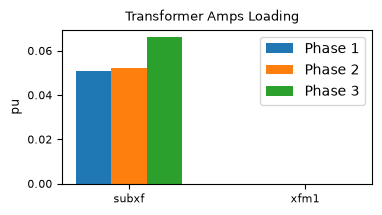

In [188]:
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()

#### Corrente nas linhas

Máximo entre as fases dividido pela `normamps`. Acima de 1 pu é sobrecarga.

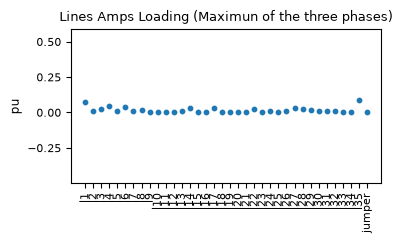

In [189]:
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)

plt.show()

#### Subestação

Potência ativa, reativa e perdas nas 24 horas. Atenção: o `abs` esconde o fluxo reverso, então pra enxergar ele o sinal original precisa aparecer no gráfico.

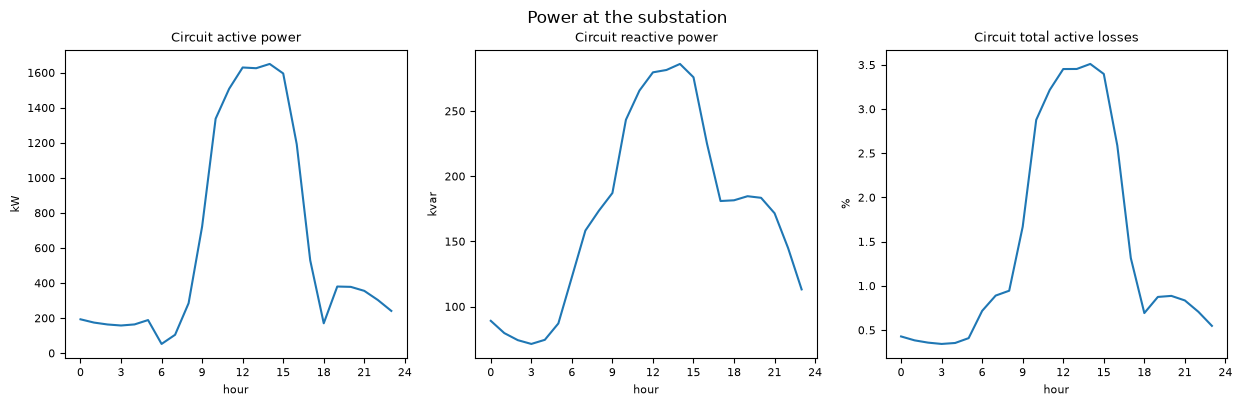

In [190]:
#*******---------Results for the substation
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []

for h in range(24):
    DSSSolution.Solve()
    Total_Act_Power.append(abs(DSSCircuit.TotalPower[0]))
    Total_React_Power.append(abs(DSSCircuit.TotalPower[1]))
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar
#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

## Simulação 5: PV true, loadmult=1, pmpp=x

Capacidade de hospedagem. Parte dos 307,125 kW por PV e vai aumentando o `pmpp` dos 8 juntos, mesmo valor pra todos, até a primeira restrição:

* sobretensão ou subtensão
* sobrecarga em linha ou transformador
* o fluxo de potência não convergir

Anotar o `pmpp` em que isso acontece e qual restrição foi.

A confirmar: o `kva` do inversor fica fixo ou cresce junto com o `pmpp`? Muda o resultado.

#### Reset e compile

Limpa tudo, compila o `ieee37.dss` e guarda as listas de nomes (cargas, barras, trafos, linhas).

In [191]:
DSSText.Command = 'reset'
DSSText.Command = 'Clear'

DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

#### Listar elementos

Só pra conferir o que foi carregado.

In [192]:
# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

List of elements
Total:73
['Vsource.source', 'Transformer.subxf', 'Transformer.xfm1', 'Line.l1', 'Line.l2', 'Line.l3', 'Line.l4', 'Line.l5', 'Line.l6', 'Line.l7', 'Line.l8', 'Line.l9', 'Line.l10', 'Line.l11', 'Line.l12', 'Line.l13', 'Line.l14', 'Line.l15', 'Line.l16', 'Line.l17', 'Line.l18', 'Line.l19', 'Line.l20', 'Line.l21', 'Line.l22', 'Line.l23', 'Line.l24', 'Line.l25', 'Line.l26', 'Line.l27', 'Line.l28', 'Line.l29', 'Line.l30', 'Line.l31', 'Line.l32', 'Line.l33', 'Line.l34', 'Line.l35', 'Transformer.reg1a', 'RegControl.creg1a', 'Transformer.reg1c', 'RegControl.creg1c', 'Line.jumper', 'Load.s701a', 'Load.s701b', 'Load.s701c', 'Load.s712c', 'Load.s713c', 'Load.s714a', 'Load.s714b', 'Load.s718a', 'Load.s720c', 'Load.s722b', 'Load.s722c', 'Load.s724b', 'Load.s725b', 'Load.s727c', 'Load.s728', 'Load.s729a', 'Load.s730c', 'Load.s731b', 'Load.s732c', 'Load.s733a', 'Load.s734c', 'Load.s735c', 'Load.s736b', 'Load.s737a', 'Load.s738a', 'Load.s740c', 'Load.s741c', 'Load.s742a', 'Load.s742b',

#### Preparar cargas

Cria as curvas residencial e industrial e liga cada carga na sua. Industriais: `s701a`, `s701b`, `s701c`, `s728`, `s737a`, `s738a`. O resto é residencial.

In [193]:
# industriais (os outros são residenciais), em minúsculo
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

#### PV systems modificado

Igual ao da sim 3, só que o `pmpp` vem da variável `pmpp_x`. Mudou o x, roda de novo a partir do Reset.

In [194]:
# muda o x aqui e roda de novo a partir do Reset
pmpp_x = 307.125   # kW de cada PV (os 8 iguais), começa no valor da sim 3
kva_inv = 340      # por enquanto fixo, falta decidir se cresce junto com o pmpp

#Define curves fo the PV System: TempxPerature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'


DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'


DSSText.Command = 'New loadshape.Irrad npts=24 interval=1  mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0] '


DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'

#### Solve

Diário, 24 passos de 1h. Limites de tensão 0,93 a 1,05 pu.

In [195]:
DSSText.Command = 'reset'

DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'

#Configure power flow options

#DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set number=1'
DSSText.Command = 'set steps=1h'
DSSText.Command = 'set hour=0'          # começa na hora 0
DSSText.Command = 'set DemandInterval=true'
DSSText.Command = 'set overloadreport=true'
DSSText.Command = 'set voltexceptionreport=true'
DSSText.Command = 'set DIVerbose=true'
DSSText.Command = 'closeDI'

# onde vou guardar o que acontece em cada hora
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # com number=1 resolve só a hora h

    # subestação (sem abs: negativo = fornecendo, positivo = fluxo reverso)
    Total_Act_Power.append(DSSCircuit.TotalPower[0])
    Total_React_Power.append(DSSCircuit.TotalPower[1])
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar

    # cargas
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#### Potência e perdas

Totais do circuito. O `TotalPower` vem negativo quando a subestação fornece energia, por isso o `abs` no percentual.

In [196]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)

Total kW delivered to the network: -1235.336 kW
Total kVAr delivered to the network: -665.302 kvar
Total active losses: 35.177 kW
Percent losses: 2.848%
Total reactive losses: 79.840 kVAr


#### Potência das cargas

kW e kvar de cada carga nas 24 horas.

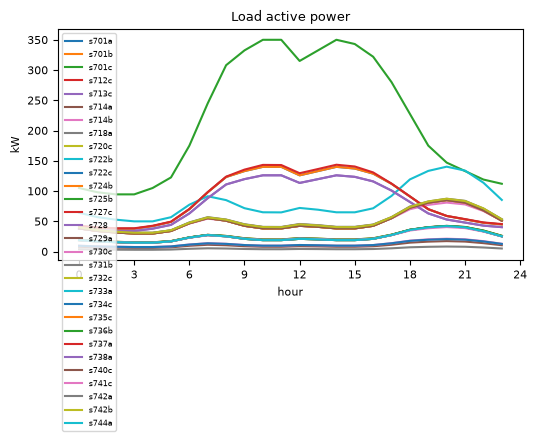

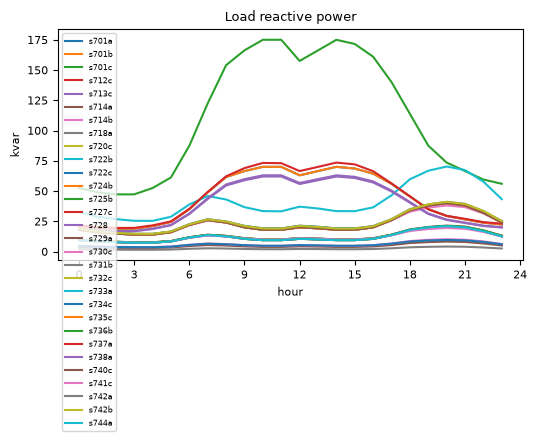

In [197]:
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # ou o Solve que você usa no loop
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers   # [P1, Q1, P2, Q2, ...]
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)



ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

#### Violações de tensão

Por fase, depois mínimo e máximo por barra. Ver quem passa de 1,05 ou cai de 0,93.

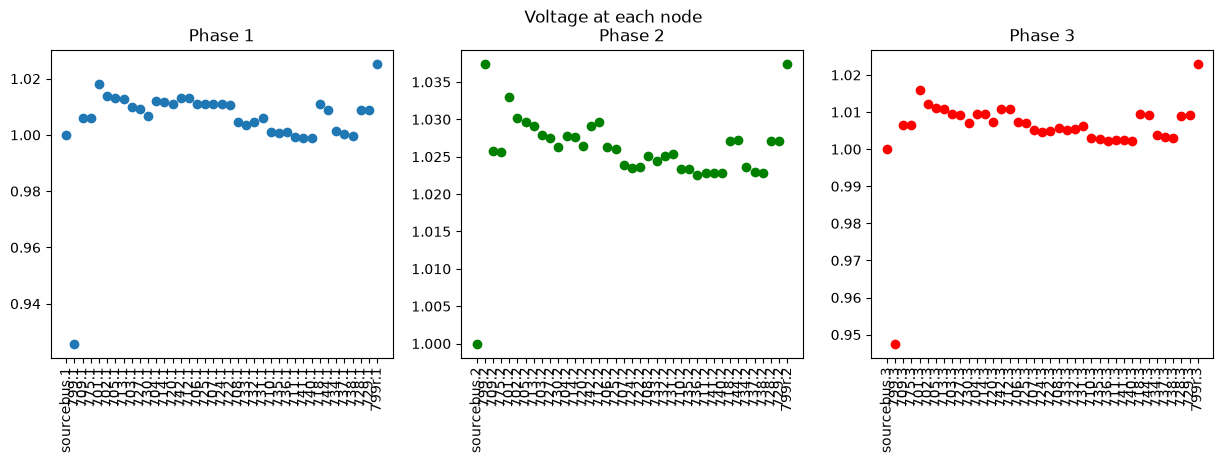

In [198]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

#### Corrente nos transformadores

Carregamento em relação ao nominal. Os reguladores ficam de fora.

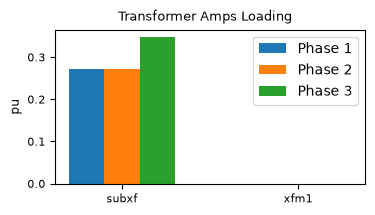

In [199]:
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()

#### Corrente nas linhas

Máximo entre as fases dividido pela `normamps`. Acima de 1 pu é sobrecarga.

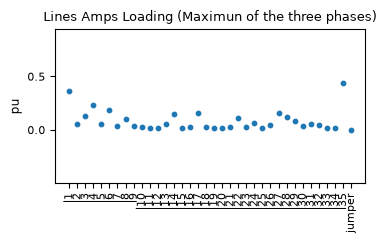

In [200]:
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)

plt.show()

#### Subestação

Potência ativa, reativa e perdas nas 24 horas. Atenção: o `abs` esconde o fluxo reverso, então pra enxergar ele o sinal original precisa aparecer no gráfico.

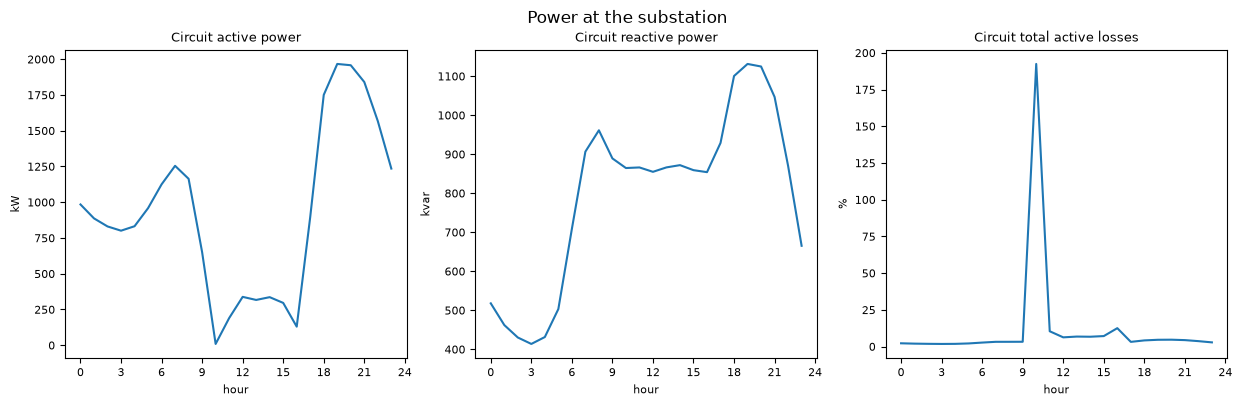

In [201]:
#*******---------Results for the substation
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []

for h in range(24):
    DSSSolution.Solve()
    Total_Act_Power.append(abs(DSSCircuit.TotalPower[0]))
    Total_React_Power.append(abs(DSSCircuit.TotalPower[1]))
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar
#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

## Simulação 6: PV true, loadmult=1, pmpp=x, storage central

Mesma base da 5, mais o `storagecentrall` depois do `pvpsys`.

* 1 unidade na barra 709
* `kWrated=2464` (soma das 8 unidades do distribuído) e `kWhrated=10000`
* `%stored=20`, `%reserve=20`, `effcurve=Eff`, `dispmode=follow`, `daily=dispatch_shape`

Objetivo: tirar o fluxo reverso e corrigir as tensões. Comparar com a 7.

#### Reset e compile

Limpa tudo, compila o `ieee37.dss` e guarda as listas de nomes (cargas, barras, trafos, linhas).

In [202]:
DSSText.Command = 'reset'
DSSText.Command = 'Clear'

DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

#### Listar elementos

Só pra conferir o que foi carregado.

In [203]:
# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

List of elements
Total:73
['Vsource.source', 'Transformer.subxf', 'Transformer.xfm1', 'Line.l1', 'Line.l2', 'Line.l3', 'Line.l4', 'Line.l5', 'Line.l6', 'Line.l7', 'Line.l8', 'Line.l9', 'Line.l10', 'Line.l11', 'Line.l12', 'Line.l13', 'Line.l14', 'Line.l15', 'Line.l16', 'Line.l17', 'Line.l18', 'Line.l19', 'Line.l20', 'Line.l21', 'Line.l22', 'Line.l23', 'Line.l24', 'Line.l25', 'Line.l26', 'Line.l27', 'Line.l28', 'Line.l29', 'Line.l30', 'Line.l31', 'Line.l32', 'Line.l33', 'Line.l34', 'Line.l35', 'Transformer.reg1a', 'RegControl.creg1a', 'Transformer.reg1c', 'RegControl.creg1c', 'Line.jumper', 'Load.s701a', 'Load.s701b', 'Load.s701c', 'Load.s712c', 'Load.s713c', 'Load.s714a', 'Load.s714b', 'Load.s718a', 'Load.s720c', 'Load.s722b', 'Load.s722c', 'Load.s724b', 'Load.s725b', 'Load.s727c', 'Load.s728', 'Load.s729a', 'Load.s730c', 'Load.s731b', 'Load.s732c', 'Load.s733a', 'Load.s734c', 'Load.s735c', 'Load.s736b', 'Load.s737a', 'Load.s738a', 'Load.s740c', 'Load.s741c', 'Load.s742a', 'Load.s742b',

#### Preparar cargas

Cria as curvas residencial e industrial e liga cada carga na sua. Industriais: `s701a`, `s701b`, `s701c`, `s728`, `s737a`, `s738a`. O resto é residencial.

In [204]:
# industriais (os outros são residenciais), em minúsculo
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

#### PV systems modificado

Igual ao da sim 3, só que o `pmpp` vem da variável `pmpp_x`. Mudou o x, roda de novo a partir do Reset.

In [205]:
# muda o x aqui e roda de novo a partir do Reset
pmpp_x = 307.125   # kW de cada PV (os 8 iguais), começa no valor da sim 3
kva_inv = 340      # por enquanto fixo, falta decidir se cresce junto com o pmpp

#Define curves fo the PV System: TempxPerature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'


DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'


DSSText.Command = 'New loadshape.Irrad npts=24 interval=1  mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0] '


DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'

#### Armazenamento central

1 storage na barra 709, `kWrated=2464` e `kWhrated=10000`.

In [206]:
# curva de eficiência e curva de despacho do storage (negativo carrega, positivo descarrega)
# a de despacho é rascunho meu, ajustar quando definir
DSSText.Command = 'New XYcurve.Eff npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'
DSSText.Command = 'New LoadShape.dispatch_shape npts=24 interval=1 mult=[0 0 0 0 0 0 0 0 0 0 -0.3 -0.4 -0.45 -0.45 -0.45 -0.4 -0.15 0.2 0.4 0.6 0.6 0.4 0.2 0]'

# 1 storage na barra 709
DSSText.Command = 'New Storage.StoCentral phases=3 bus1=709.1.2.3 kv=4.8 conn=delta kWrated=2464 kWhrated=10000 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'

#### Solve

Diário, 24 passos de 1h. Limites de tensão 0,93 a 1,05 pu.

In [207]:
DSSText.Command = 'reset'

DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'

#Configure power flow options

#DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set number=1'
DSSText.Command = 'set steps=1h'
DSSText.Command = 'set hour=0'          # começa na hora 0
DSSText.Command = 'set DemandInterval=true'
DSSText.Command = 'set overloadreport=true'
DSSText.Command = 'set voltexceptionreport=true'
DSSText.Command = 'set DIVerbose=true'
DSSText.Command = 'closeDI'

# onde vou guardar o que acontece em cada hora
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # com number=1 resolve só a hora h

    # subestação (sem abs: negativo = fornecendo, positivo = fluxo reverso)
    Total_Act_Power.append(DSSCircuit.TotalPower[0])
    Total_React_Power.append(DSSCircuit.TotalPower[1])
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar

    # cargas
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#### Potência e perdas

Totais do circuito. O `TotalPower` vem negativo quando a subestação fornece energia, por isso o `abs` no percentual.

In [208]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)

Total kW delivered to the network: -1266.143 kW
Total kVAr delivered to the network: -668.484 kvar
Total active losses: 36.617 kW
Percent losses: 2.892%
Total reactive losses: 83.371 kVAr


#### Potência das cargas

kW e kvar de cada carga nas 24 horas.

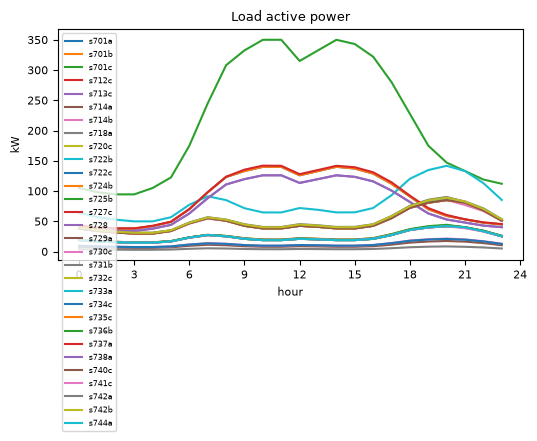

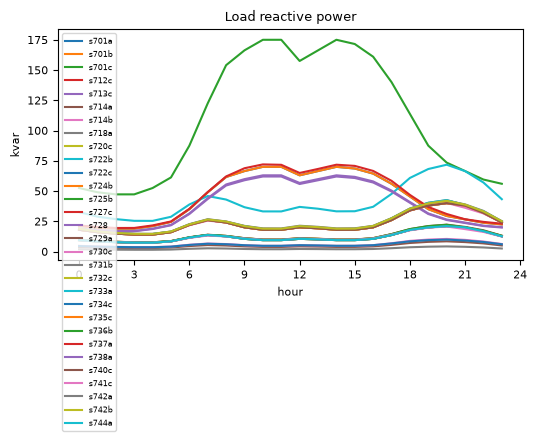

In [209]:
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # ou o Solve que você usa no loop
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers   # [P1, Q1, P2, Q2, ...]
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)



ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

#### Violações de tensão

Por fase, depois mínimo e máximo por barra. Ver quem passa de 1,05 ou cai de 0,93.

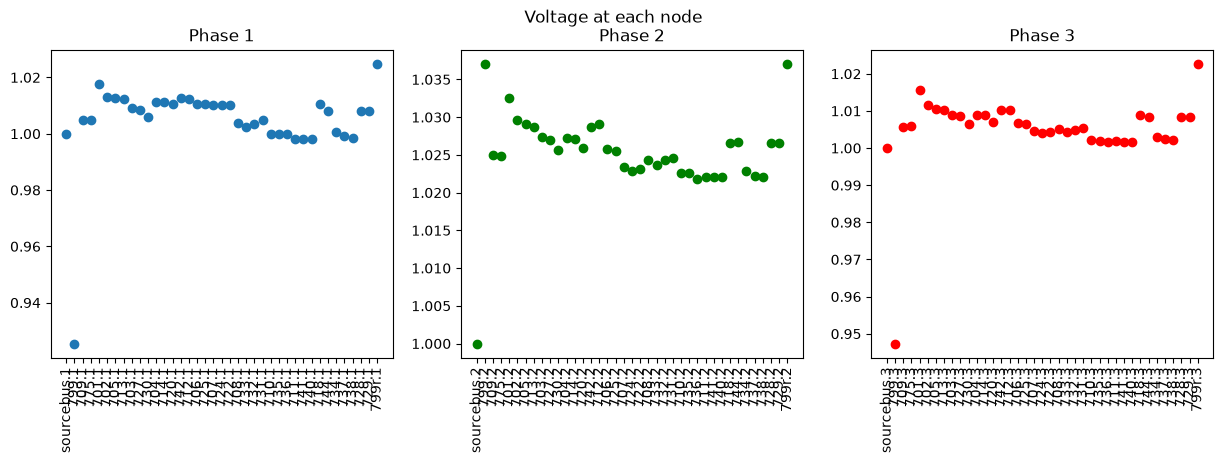

In [210]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

#### Corrente nos transformadores

Carregamento em relação ao nominal. Os reguladores ficam de fora.

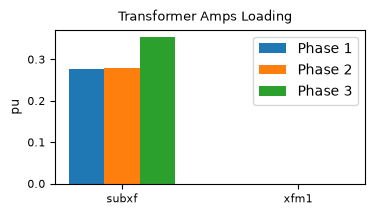

In [211]:
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()

#### Corrente nas linhas

Máximo entre as fases dividido pela `normamps`. Acima de 1 pu é sobrecarga.

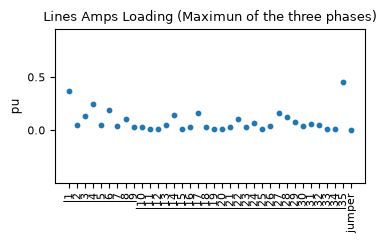

In [212]:
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)

plt.show()

#### Subestação

Potência ativa, reativa e perdas nas 24 horas. Atenção: o `abs` esconde o fluxo reverso, então pra enxergar ele o sinal original precisa aparecer no gráfico.

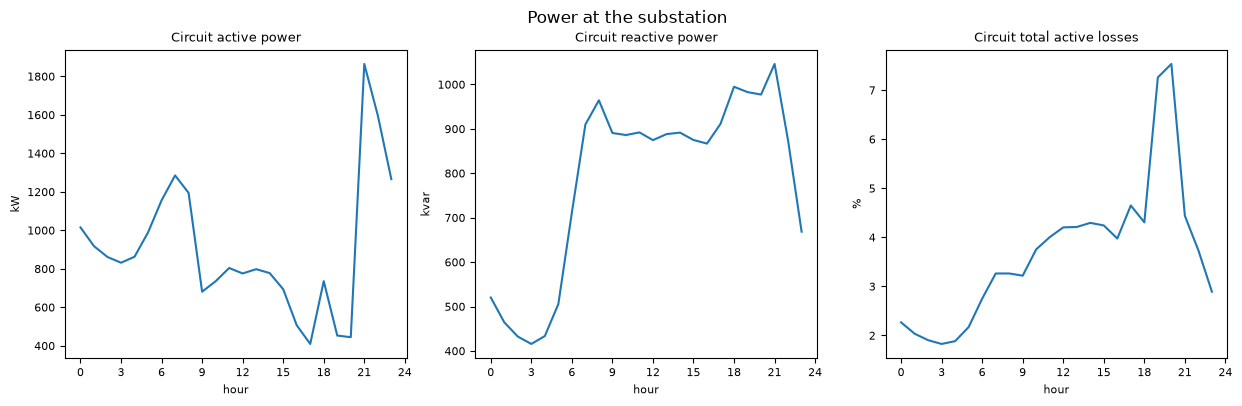

In [213]:
#*******---------Results for the substation
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []

for h in range(24):
    DSSSolution.Solve()
    Total_Act_Power.append(abs(DSSCircuit.TotalPower[0]))
    Total_React_Power.append(abs(DSSCircuit.TotalPower[1]))
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar
#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

## Simulação 7: PV true, loadmult=1, pmpp=x, storage distribuído

Mesma base da 5, mais o `storagedist` depois do `pvpsys`.

* 8 unidades, uma em cada barra de PV: 728, 733, 737, 740, 718, 720, 722, 742
* `kWrated=308` e `kWhrated=1250` cada (10000 kWh no total)
* `%stored=20`, `%reserve=20`, `effcurve=Eff`, `dispmode=follow`, `daily=dispatch_shape`

Mesma energia total da 6, pra comparação ser justa. Comparar tensão, perdas, fluxo reverso e sobrecarga.

#### Reset e compile

Limpa tudo, compila o `ieee37.dss` e guarda as listas de nomes (cargas, barras, trafos, linhas).

In [214]:
DSSText.Command = 'reset'
DSSText.Command = 'Clear'

DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

#### Listar elementos

Só pra conferir o que foi carregado.

In [215]:
# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

List of elements
Total:73
['Vsource.source', 'Transformer.subxf', 'Transformer.xfm1', 'Line.l1', 'Line.l2', 'Line.l3', 'Line.l4', 'Line.l5', 'Line.l6', 'Line.l7', 'Line.l8', 'Line.l9', 'Line.l10', 'Line.l11', 'Line.l12', 'Line.l13', 'Line.l14', 'Line.l15', 'Line.l16', 'Line.l17', 'Line.l18', 'Line.l19', 'Line.l20', 'Line.l21', 'Line.l22', 'Line.l23', 'Line.l24', 'Line.l25', 'Line.l26', 'Line.l27', 'Line.l28', 'Line.l29', 'Line.l30', 'Line.l31', 'Line.l32', 'Line.l33', 'Line.l34', 'Line.l35', 'Transformer.reg1a', 'RegControl.creg1a', 'Transformer.reg1c', 'RegControl.creg1c', 'Line.jumper', 'Load.s701a', 'Load.s701b', 'Load.s701c', 'Load.s712c', 'Load.s713c', 'Load.s714a', 'Load.s714b', 'Load.s718a', 'Load.s720c', 'Load.s722b', 'Load.s722c', 'Load.s724b', 'Load.s725b', 'Load.s727c', 'Load.s728', 'Load.s729a', 'Load.s730c', 'Load.s731b', 'Load.s732c', 'Load.s733a', 'Load.s734c', 'Load.s735c', 'Load.s736b', 'Load.s737a', 'Load.s738a', 'Load.s740c', 'Load.s741c', 'Load.s742a', 'Load.s742b',

#### Preparar cargas

Cria as curvas residencial e industrial e liga cada carga na sua. Industriais: `s701a`, `s701b`, `s701c`, `s728`, `s737a`, `s738a`. O resto é residencial.

In [216]:
# industriais (os outros são residenciais), em minúsculo
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

#### PV systems modificado

Igual ao da sim 3, só que o `pmpp` vem da variável `pmpp_x`. Mudou o x, roda de novo a partir do Reset.

In [217]:
# muda o x aqui e roda de novo a partir do Reset
pmpp_x = 307.125   # kW de cada PV (os 8 iguais), começa no valor da sim 3
kva_inv = 340      # por enquanto fixo, falta decidir se cresce junto com o pmpp

#Define curves fo the PV System: TempxPerature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'


DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'


DSSText.Command = 'New loadshape.Irrad npts=24 interval=1  mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0] '


DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'

#### Armazenamento distribuído

8 storages, um em cada barra de PV, `kWrated=308` e `kWhrated=1250` cada.

In [218]:
# curva de eficiência e curva de despacho do storage (negativo carrega, positivo descarrega)
# a de despacho é rascunho meu, ajustar quando definir
DSSText.Command = 'New XYcurve.Eff npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'
DSSText.Command = 'New LoadShape.dispatch_shape npts=24 interval=1 mult=[0 0 0 0 0 0 0 0 0 0 -0.3 -0.4 -0.45 -0.45 -0.45 -0.4 -0.15 0.2 0.4 0.6 0.6 0.4 0.2 0]'

# 8 storages, um em cada barra de PV
DSSText.Command = 'New Storage.StoDist_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'

#### Solve

Diário, 24 passos de 1h. Limites de tensão 0,93 a 1,05 pu.

In [219]:
DSSText.Command = 'reset'

DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'

#Configure power flow options

#DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set number=1'
DSSText.Command = 'set steps=1h'
DSSText.Command = 'set hour=0'          # começa na hora 0
DSSText.Command = 'set DemandInterval=true'
DSSText.Command = 'set overloadreport=true'
DSSText.Command = 'set voltexceptionreport=true'
DSSText.Command = 'set DIVerbose=true'
DSSText.Command = 'closeDI'

# onde vou guardar o que acontece em cada hora
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # com number=1 resolve só a hora h

    # subestação (sem abs: negativo = fornecendo, positivo = fluxo reverso)
    Total_Act_Power.append(DSSCircuit.TotalPower[0])
    Total_React_Power.append(DSSCircuit.TotalPower[1])
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar

    # cargas
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#### Potência e perdas

Totais do circuito. O `TotalPower` vem negativo quando a subestação fornece energia, por isso o `abs` no percentual.

In [220]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)

Total kW delivered to the network: -1266.140 kW
Total kVAr delivered to the network: -668.440 kvar
Total active losses: 36.609 kW
Percent losses: 2.891%
Total reactive losses: 83.329 kVAr


#### Potência das cargas

kW e kvar de cada carga nas 24 horas.

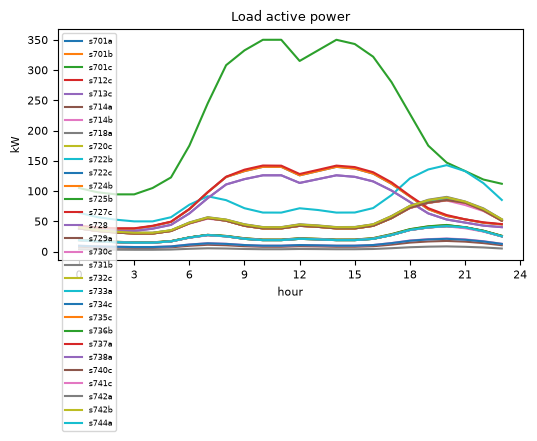

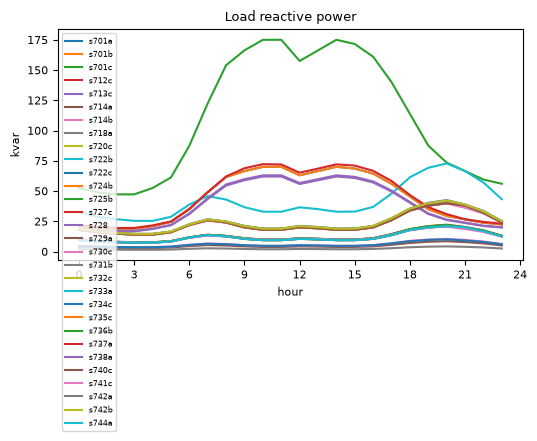

In [221]:
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # ou o Solve que você usa no loop
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers   # [P1, Q1, P2, Q2, ...]
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)



ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

#### Violações de tensão

Por fase, depois mínimo e máximo por barra. Ver quem passa de 1,05 ou cai de 0,93.

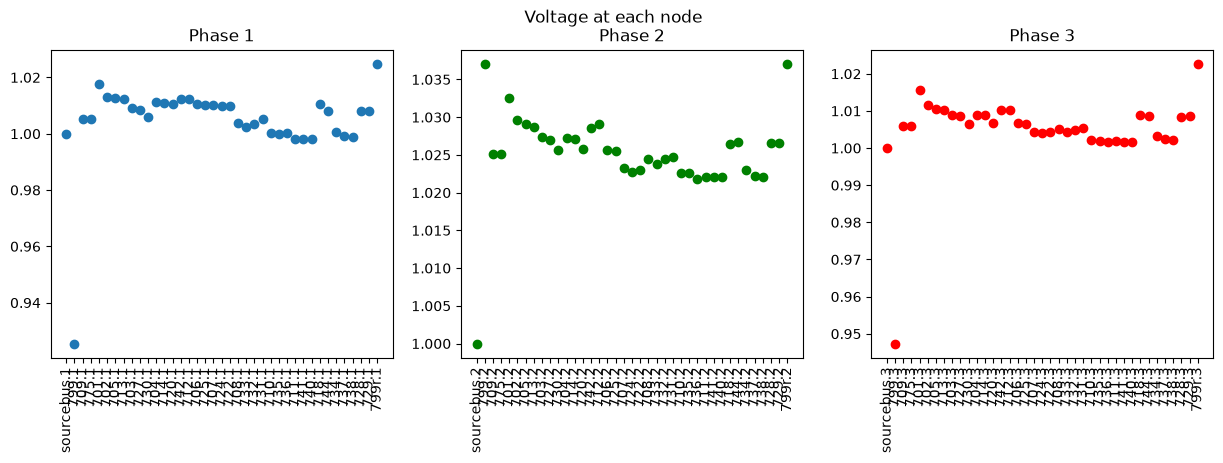

In [222]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

#### Corrente nos transformadores

Carregamento em relação ao nominal. Os reguladores ficam de fora.

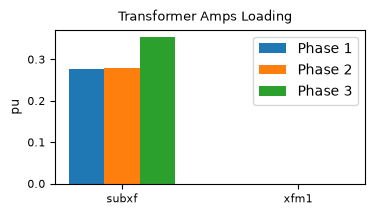

In [223]:
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()

#### Corrente nas linhas

Máximo entre as fases dividido pela `normamps`. Acima de 1 pu é sobrecarga.

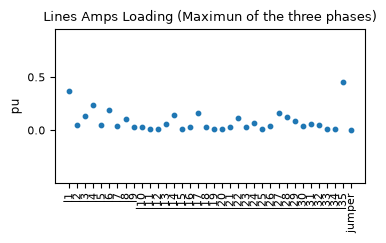

In [224]:
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)

plt.show()

#### Subestação

Potência ativa, reativa e perdas nas 24 horas. Atenção: o `abs` esconde o fluxo reverso, então pra enxergar ele o sinal original precisa aparecer no gráfico.

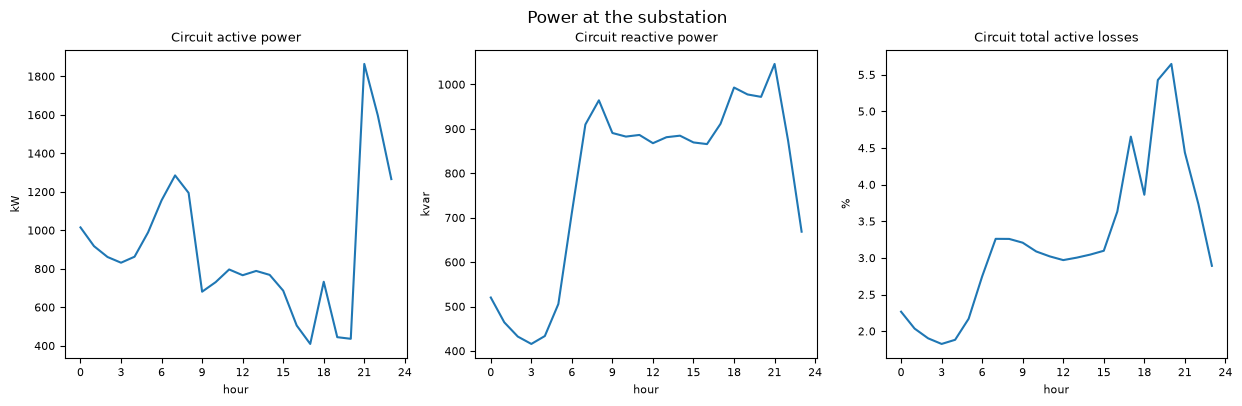

In [225]:
#*******---------Results for the substation
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []

for h in range(24):
    DSSSolution.Solve()
    Total_Act_Power.append(abs(DSSCircuit.TotalPower[0]))
    Total_React_Power.append(abs(DSSCircuit.TotalPower[1]))
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar
#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

## Simulação 8: microrrede 

**Ilhamento**

* Abrir a `L27` no terminal 1 (`Open Line.L27 Term=1`). Ela liga a 730 na 709.
* Rodando a topologia no `.dss`, a ilha fica com as barras 708, 709, 710, 711, 731, 732, 733, 734, 735, 736, 737, 738, 740, 741 e 775.
* PVs dentro da ilha: 733, 737, 740. Storage distribuído nessas mesmas. Storage central na 709.

**Storage**

* Começa 100% carregado (`%stored=100`) e desconectado da rede desde a hora 0.
* Grid forming: `New InvControl.StoCtrl DERList=[...] mode=GFM` e o storage em `State=Discharging ControlMode=GFM`.
* Rodar com o central e com o distribuído.

**Corte de carga**

* Industrial fica, residencial sai. Cortar em etapas, da menor prioridade pra maior, e ver quanto o tempo de sobrevivência aumenta em cada uma.
* Comparar sobrevivência com corte e sem corte.


# carga (kW) e prioridade de corte (menor prioridade primeiro)

[('S736b',42),('S741c',42),('S732c',42),('S734c',42),('S735c',85),('S733a',85),('S740c',85),('S738a',126),('S737a',140)]


**Métrica:** tempo de sobrevivência.

#### Reset e compile

Limpa tudo, compila o `ieee37.dss` e guarda as listas de nomes (cargas, barras, trafos, linhas).

In [226]:
DSSText.Command = 'reset'
DSSText.Command = 'Clear'

DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

#### Listar elementos

Só pra conferir o que foi carregado.

In [227]:
# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

List of elements
Total:73
['Vsource.source', 'Transformer.subxf', 'Transformer.xfm1', 'Line.l1', 'Line.l2', 'Line.l3', 'Line.l4', 'Line.l5', 'Line.l6', 'Line.l7', 'Line.l8', 'Line.l9', 'Line.l10', 'Line.l11', 'Line.l12', 'Line.l13', 'Line.l14', 'Line.l15', 'Line.l16', 'Line.l17', 'Line.l18', 'Line.l19', 'Line.l20', 'Line.l21', 'Line.l22', 'Line.l23', 'Line.l24', 'Line.l25', 'Line.l26', 'Line.l27', 'Line.l28', 'Line.l29', 'Line.l30', 'Line.l31', 'Line.l32', 'Line.l33', 'Line.l34', 'Line.l35', 'Transformer.reg1a', 'RegControl.creg1a', 'Transformer.reg1c', 'RegControl.creg1c', 'Line.jumper', 'Load.s701a', 'Load.s701b', 'Load.s701c', 'Load.s712c', 'Load.s713c', 'Load.s714a', 'Load.s714b', 'Load.s718a', 'Load.s720c', 'Load.s722b', 'Load.s722c', 'Load.s724b', 'Load.s725b', 'Load.s727c', 'Load.s728', 'Load.s729a', 'Load.s730c', 'Load.s731b', 'Load.s732c', 'Load.s733a', 'Load.s734c', 'Load.s735c', 'Load.s736b', 'Load.s737a', 'Load.s738a', 'Load.s740c', 'Load.s741c', 'Load.s742a', 'Load.s742b',

#### Preparar cargas

Cria as curvas residencial e industrial e liga cada carga na sua. Industriais: `s701a`, `s701b`, `s701c`, `s728`, `s737a`, `s738a`. O resto é residencial.

In [228]:
# industriais (os outros são residenciais), em minúsculo
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

#### PV systems

8 PVs com `pmpp=307.125` (soma = 2457 kW, igual à soma das cargas). Também cria as curvas de irradiância, temperatura, eficiência e PvsT.

In [229]:
#Define curves fo the PV System: TempxPerature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'


DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'


DSSText.Command = 'New loadshape.Irrad npts=24 interval=1  mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0] '


DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'

#### Armazenamento 

Deixei o central montado pra testar. Começa com `%stored=100`. O GFM está comentado até validar.

In [230]:
# curva de eficiência e curva de despacho do storage (negativo carrega, positivo descarrega)
# a de despacho é rascunho meu, ajustar quando definir
DSSText.Command = 'New XYcurve.Eff npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'
DSSText.Command = 'New LoadShape.dispatch_shape npts=24 interval=1 mult=[0 0 0 0 0 0 0 0 0 0 -0.3 -0.4 -0.45 -0.45 -0.45 -0.4 -0.15 0.2 0.4 0.6 0.6 0.4 0.2 0]'

# AINDA A DEFINIR: central ou distribuído, potência e energia. Deixei o central pra testar.
# começa 100% carregado (%stored=100)
DSSText.Command = 'New Storage.StoCentral phases=3 bus1=709.1.2.3 kv=4.8 conn=delta kWrated=2464 kWhrated=10000 %stored=100 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'

# grid forming, falta validar na versão do OpenDSS, por isso fica comentado
# DSSText.Command = 'New InvControl.StoCtrl DERList=[Storage.StoCentral] mode=GFM'

#### Ilhamento e corte de carga

Abre a `L27` e corta as cargas da lista `CARGAS_ILHA` pela ordem. `N_CORTE` diz quantas.

In [231]:
# ilhamento: abre a L27 no terminal 1 (liga a 730 na 709)
DSSText.Command = 'Open Line.L27 Term=1'

# carga (kW) e prioridade de corte, menor prioridade primeiro (ainda a confirmar)
CARGAS_ILHA = [('S736b',42),('S741c',42),('S732c',42),('S734c',42),('S735c',85),
               ('S733a',85),('S740c',85),('S738a',126),('S737a',140)]

N_CORTE = 0   # quantas cargas cortar, na ordem da lista (0 = sem corte). Muda e roda de novo a partir do Reset
for nome, kw in CARGAS_ILHA[:N_CORTE]:
    DSSText.Command = 'Edit Load.' + nome + ' enabled=no'

#### Solve

Diário, 24 passos de 1h. Limites de tensão 0,93 a 1,05 pu.

In [232]:
DSSText.Command = 'reset'

DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'

#Configure power flow options

#DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set number=1'
DSSText.Command = 'set steps=1h'
DSSText.Command = 'set hour=0'          # começa na hora 0
DSSText.Command = 'set DemandInterval=true'
DSSText.Command = 'set overloadreport=true'
DSSText.Command = 'set voltexceptionreport=true'
DSSText.Command = 'set DIVerbose=true'
DSSText.Command = 'closeDI'

# onde vou guardar o que acontece em cada hora
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # com number=1 resolve só a hora h

    # subestação (sem abs: negativo = fornecendo, positivo = fluxo reverso)
    Total_Act_Power.append(DSSCircuit.TotalPower[0])
    Total_React_Power.append(DSSCircuit.TotalPower[1])
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar

    # cargas
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#### Potência e perdas

Totais do circuito. O `TotalPower` vem negativo quando a subestação fornece energia, por isso o `abs` no percentual.

In [233]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)

Total kW delivered to the network: -821.412 kW
Total kVAr delivered to the network: -426.677 kvar
Total active losses: 14.538 kW
Percent losses: 1.770%
Total reactive losses: 32.136 kVAr


#### Potência das cargas

kW e kvar de cada carga nas 24 horas.

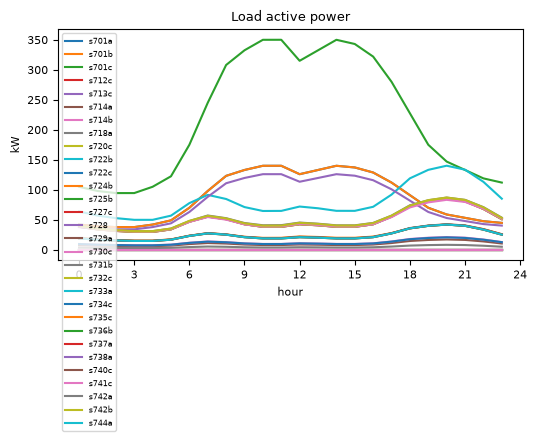

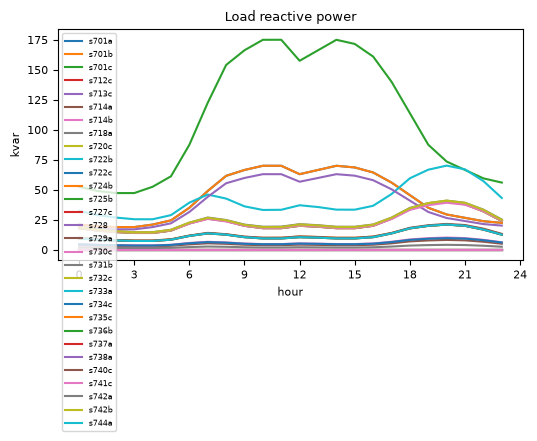

In [234]:
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.Solve()   # ou o Solve que você usa no loop
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers   # [P1, Q1, P2, Q2, ...]
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)



ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

#### Violações de tensão

Por fase, depois mínimo e máximo por barra. Ver quem passa de 1,05 ou cai de 0,93.

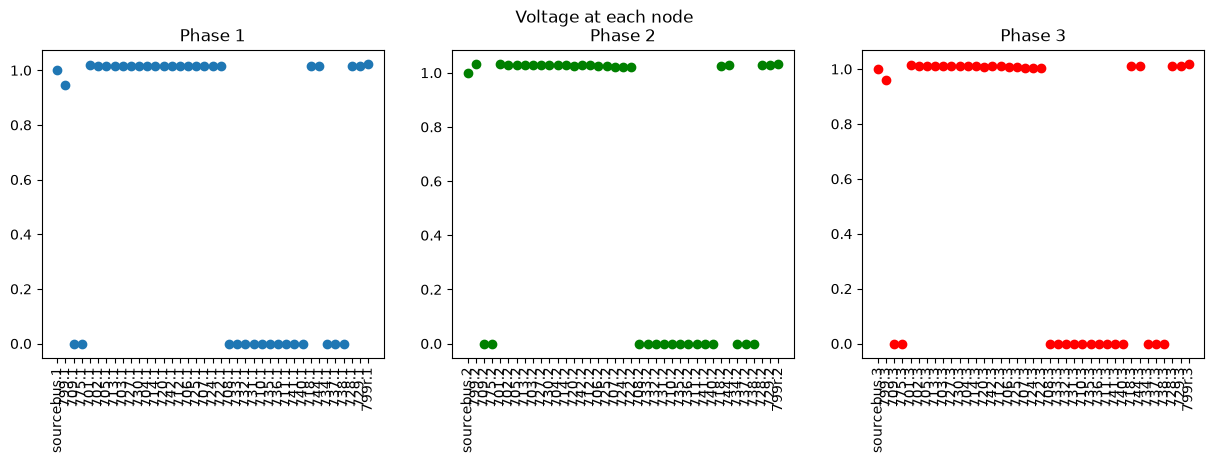

In [235]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

#### Corrente nos transformadores

Carregamento em relação ao nominal. Os reguladores ficam de fora.

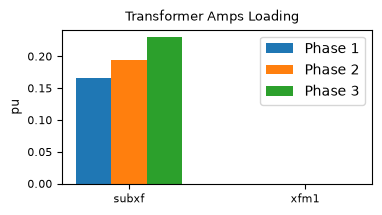

In [236]:
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()

#### Corrente nas linhas

Máximo entre as fases dividido pela `normamps`. Acima de 1 pu é sobrecarga.

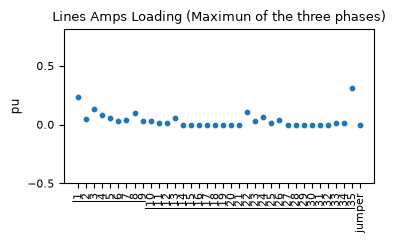

In [237]:
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)

plt.show()

#### Subestação

Potência ativa, reativa e perdas nas 24 horas. Atenção: o `abs` esconde o fluxo reverso, então pra enxergar ele o sinal original precisa aparecer no gráfico.

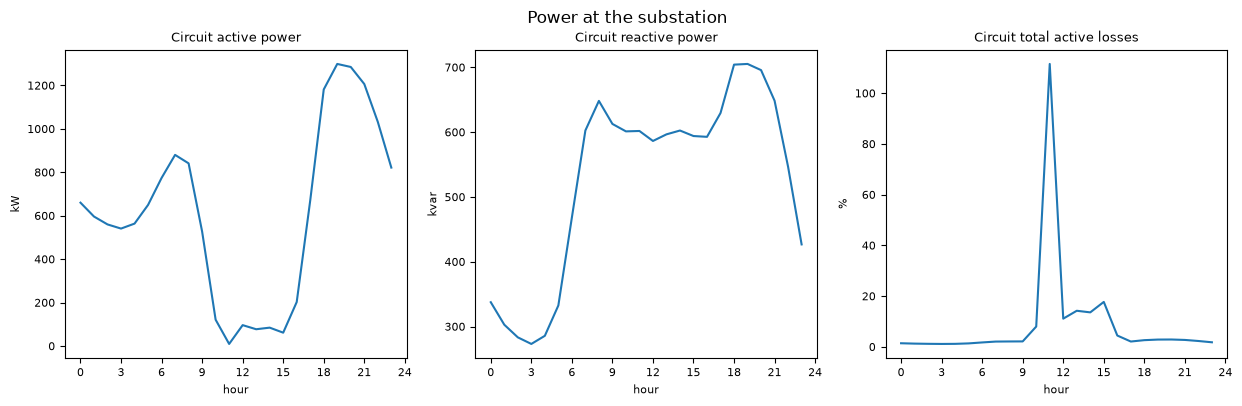

In [238]:
#*******---------Results for the substation
Total_Act_Power = []
Total_React_Power = []
Total_Act_Losses = []
Total_React_Losses = []

for h in range(24):
    DSSSolution.Solve()
    Total_Act_Power.append(abs(DSSCircuit.TotalPower[0]))
    Total_React_Power.append(abs(DSSCircuit.TotalPower[1]))
    Total_Act_Losses.append(DSSCircuit.Losses[0] / 1000)   # W to kW
    Total_React_Losses.append(DSSCircuit.Losses[1] / 1000) # var to kvar
#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()